--- 4.1 DESKRIPSI DATASET ---
Dimensi data awal: 1466 baris, 23 kolom


/tmp/ipykernel_2514/1330524985.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='Rabid', data=df, palette='viridis')


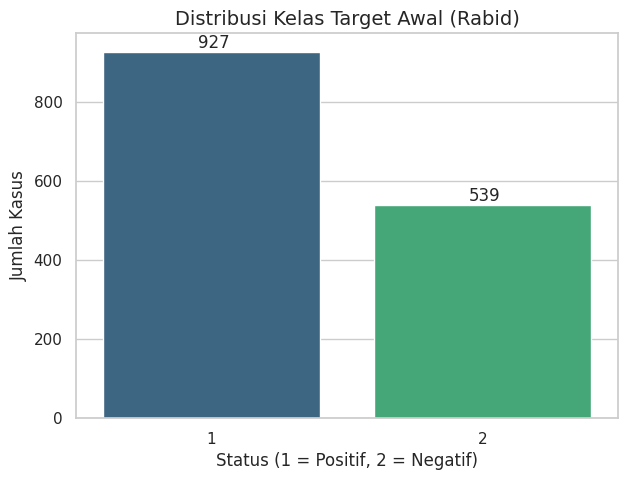


--- 4.2 PREPROCESSING DATA ---
Jumlah Missing Value per atribut sebelum preprocessing:
Education       1
Transmission    1
dtype: int64

Dimensi data setelah hapus missing value: 1464 baris, 23 kolom
Kolom 'Respondent_ID' berhasil dihapus.

Contoh hasil Encoding (5 Data Pertama):
   Education_encoded  Rabid
0                  4      0
1                  4      1
2                  4      1
3                  4      1
4                  4      1

--- 4.3 PEMBAGIAN DATASET ---


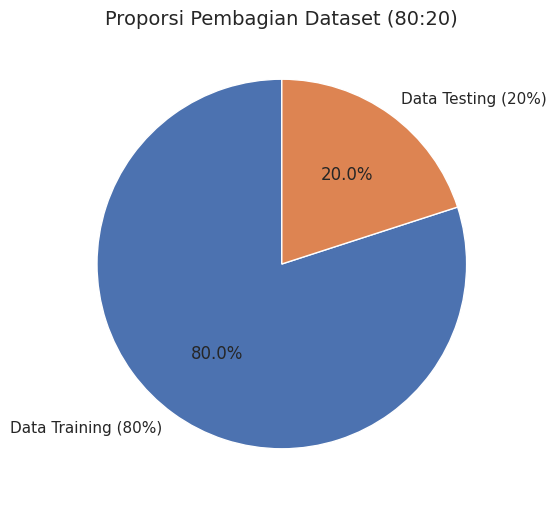

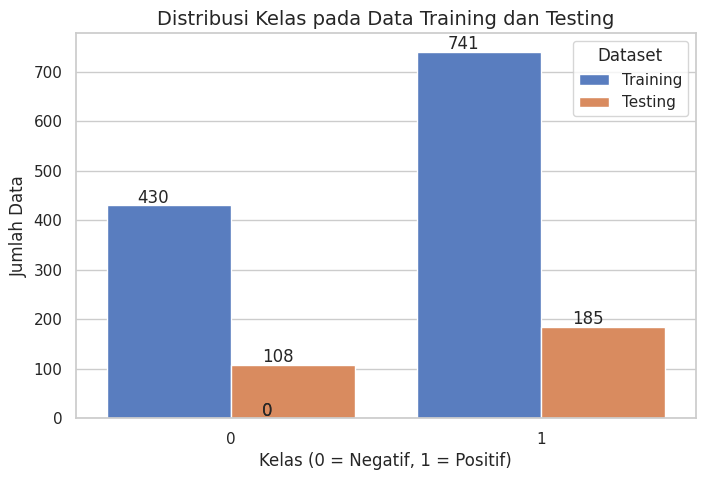


--- 4.4 IMPLEMENTASI ALGORITMA ---
Model Random Forest berhasil dilatih dengan n_estimators=100


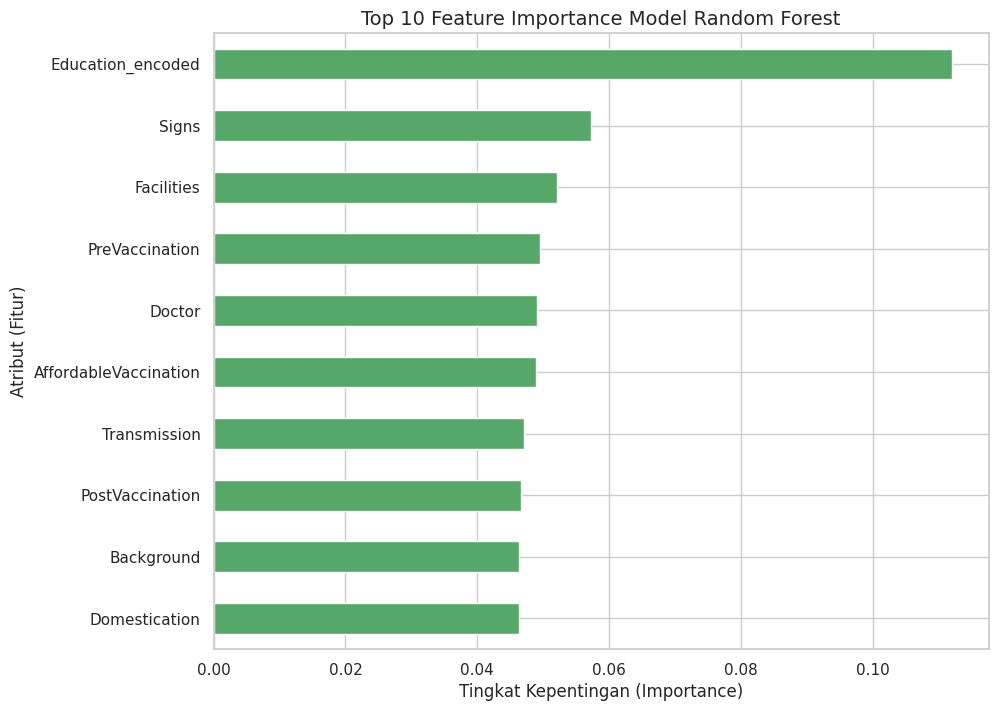


--- 4.5 EVALUASI MODEL ---


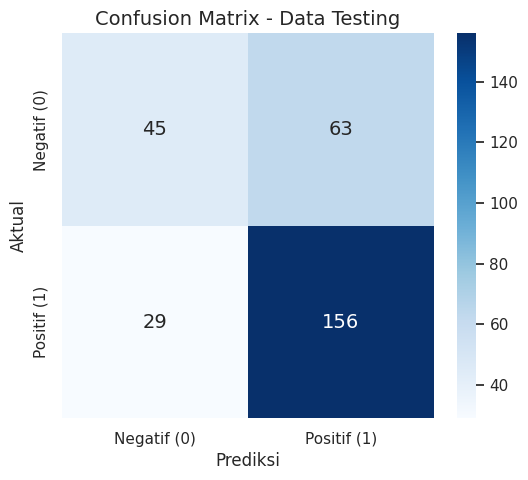

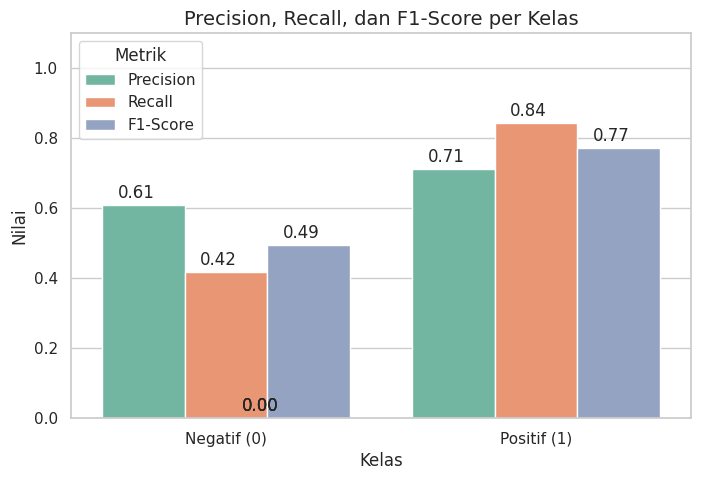

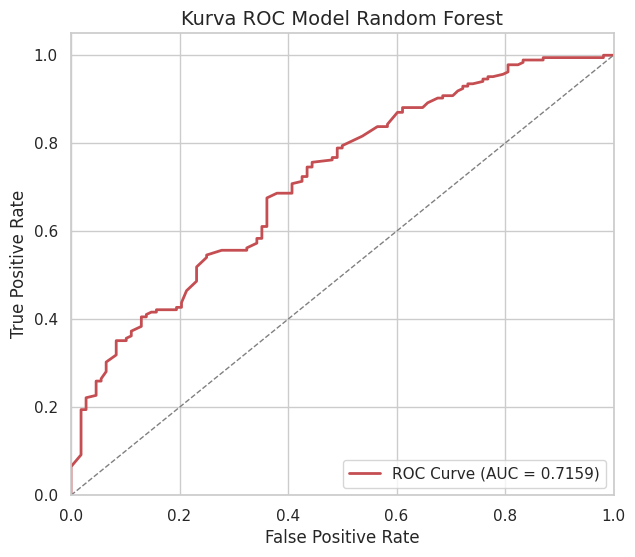


Classification Report Lengkap:
              precision    recall  f1-score   support

 Negatif (0)       0.61      0.42      0.49       108
 Positif (1)       0.71      0.84      0.77       185

    accuracy                           0.69       293
   macro avg       0.66      0.63      0.63       293
weighted avg       0.67      0.69      0.67       293

Accuracy Keseluruhan: 0.6860


In [ ]:
# ==============================================================================
# IMPORT LIBRARY YANG DIBUTUHKAN
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, precision_recall_fscore_support
from sklearn.preprocessing import LabelEncoder

# Set style untuk visualisasi agar rapi
sns.set_theme(style="whitegrid")

# ==============================================================================
# 4.1 DESKRIPSI DATASET
# ==============================================================================
print("--- 4.1 DESKRIPSI DATASET ---")
df = pd.read_csv("rabies_dataset.csv")
print(f"Dimensi data awal: {df.shape[0]} baris, {df.shape[1]} kolom")

# Visualisasi 1: Distribusi Target 'Rabid'
plt.figure(figsize=(7, 5))
ax = sns.countplot(x='Rabid', data=df, palette='viridis')
plt.title('Distribusi Kelas Target Awal (Rabid)', fontsize=14)
plt.xlabel('Status (1 = Positif, 2 = Negatif)', fontsize=12)
plt.ylabel('Jumlah Kasus', fontsize=12)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + 0.35, p.get_height() + 10))
plt.show()

# ==============================================================================
# 4.2 HASIL PREPROCESSING DATA
# ==============================================================================
print("\n--- 4.2 PREPROCESSING DATA ---")

# 4.2.1 Penanganan Missing Value
missing = df.isnull().sum()
print("Jumlah Missing Value per atribut sebelum preprocessing:")
print(missing[missing > 0])

# Drop baris yang kosong (karena sangat sedikit)
df = df.dropna()
print(f"\nDimensi data setelah hapus missing value: {df.shape[0]} baris, {df.shape[1]} kolom")

# Menghapus atribut yang tidak dipakai
if 'Respondent_ID' in df.columns:
    df = df.drop(columns=['Respondent_ID'])
    print("Kolom 'Respondent_ID' berhasil dihapus.")

# 4.2.2 Pengkodean Data Kategorikal (Encoding)
le = LabelEncoder()
df['Education_encoded'] = le.fit_transform(df['Education'])
df = df.drop(columns=['Education'])

# Menyamakan format target menjadi 0 dan 1 untuk mempermudah evaluasi
# Aktual: 1 (Positif Rabies), 2 (Negatif Rabies) -> Diubah: 1 (Positif), 0 (Negatif)
df['Rabid'] = df['Rabid'].apply(lambda x: 1 if x == 1 else 0)

print("\nContoh hasil Encoding (5 Data Pertama):")
print(df[['Education_encoded', 'Rabid']].head())

# ==============================================================================
# 4.3 PEMBAGIAN DATASET (SPLITTING)
# ==============================================================================
print("\n--- 4.3 PEMBAGIAN DATASET ---")
X = df.drop(columns=['Rabid'])
y = df['Rabid']

# Split 80:20 secara stratified
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Visualisasi 2: Pie Chart Proporsi Pembagian Data
plt.figure(figsize=(6, 6))
plt.pie([len(X_train), len(X_test)], labels=['Data Training (80%)', 'Data Testing (20%)'],
        autopct='%1.1f%%', colors=['#4c72b0', '#dd8452'], startangle=90, wedgeprops={'edgecolor': 'white'})
plt.title('Proporsi Pembagian Dataset (80:20)', fontsize=14)
plt.show()

# Visualisasi 3: Bar Chart Distribusi Kelas Training vs Testing
train_counts = y_train.value_counts().rename('Training')
test_counts = y_test.value_counts().rename('Testing')
dist_df = pd.concat([train_counts, test_counts], axis=1).fillna(0).reset_index()
dist_df = dist_df.melt(id_vars='Rabid', var_name='Dataset', value_name='Jumlah')

plt.figure(figsize=(8, 5))
ax2 = sns.barplot(x='Rabid', y='Jumlah', hue='Dataset', data=dist_df, palette='muted')
plt.title('Distribusi Kelas pada Data Training dan Testing', fontsize=14)
plt.xlabel('Kelas (0 = Negatif, 1 = Positif)', fontsize=12)
plt.ylabel('Jumlah Data', fontsize=12)
for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height())}', (p.get_x() + 0.1, p.get_height() + 5))
plt.show()

# ==============================================================================
# 4.4 IMPLEMENTASI ALGORITMA RANDOM FOREST
# ==============================================================================
print("\n--- 4.4 IMPLEMENTASI ALGORITMA ---")
# Melatih model
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)
print("Model Random Forest berhasil dilatih dengan n_estimators=100")

# Visualisasi 4: Feature Importance
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 8))
importances.tail(10).plot(kind='barh', color='#55a868')
plt.title('Top 10 Feature Importance Model Random Forest', fontsize=14)
plt.xlabel('Tingkat Kepentingan (Importance)', fontsize=12)
plt.ylabel('Atribut (Fitur)', fontsize=12)
plt.show()

# ==============================================================================
# 4.5 EVALUASI PERFORMA MODEL
# ==============================================================================
print("\n--- 4.5 EVALUASI MODEL ---")
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

# Visualisasi 5: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14},
            xticklabels=['Negatif (0)', 'Positif (1)'],
            yticklabels=['Negatif (0)', 'Positif (1)'])
plt.title('Confusion Matrix - Data Testing', fontsize=14)
plt.xlabel('Prediksi', fontsize=12)
plt.ylabel('Aktual', fontsize=12)
plt.show()

# Visualisasi 6: Bar Chart Precision, Recall, F1-Score
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred)
metrics_df = pd.DataFrame({
    'Kelas': ['Negatif (0)', 'Positif (1)'],
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1
})
metrics_melted = metrics_df.melt(id_vars='Kelas', var_name='Metrik', value_name='Nilai')

plt.figure(figsize=(8, 5))
ax3 = sns.barplot(x='Kelas', y='Nilai', hue='Metrik', data=metrics_melted, palette='Set2')
plt.title('Precision, Recall, dan F1-Score per Kelas', fontsize=14)
plt.ylim(0, 1.1)
for p in ax3.patches:
    ax3.annotate(f'{p.get_height():.2f}', (p.get_x() + 0.05, p.get_height() + 0.02))
plt.show()

# Visualisasi 7: Kurva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='#c44e52', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Kurva ROC Model Random Forest', fontsize=14)
plt.legend(loc="lower right")
plt.show()

print("\nClassification Report Lengkap:")
print(classification_report(y_test, y_pred, target_names=['Negatif (0)', 'Positif (1)']))
print(f"Accuracy Keseluruhan: {accuracy_score(y_test, y_pred):.4f}")

Nilai AUC (Area Under Curve): 0.7159


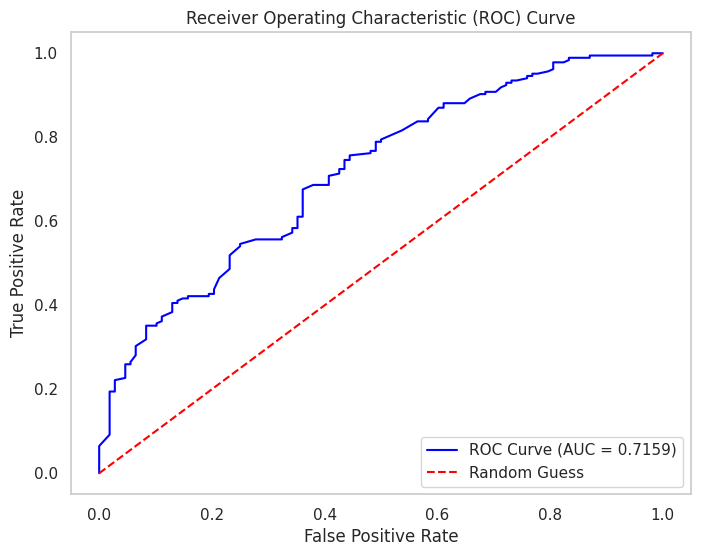

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# 1. Menghitung probabilitas prediksi untuk kelas positif (1)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

# 2. Menghitung nilai AUC
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"Nilai AUC (Area Under Curve): {auc_score:.4f}")

# (Opsional) 3. Menampilkan Kurva ROC lengkap dengan nilai AUC di legendanya
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Guess')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid()
plt.show()